# Day 5(M1 Day05) 확장 실습 — 웹 조사 리서치 팀: 조사원·작성자·검증자 (자율 구현)

**목표**: 본 실습의 리서치 팀은 고정된 내부 자료(`SOURCE`)로 일했다. 이번에는 **실시간 웹 뉴스**를 자료로 쓴다. 자료를 찾아 거르는 **조사원**을 팀에 더하고, 검증 게이트는 기사 번호(출처)를 코드로 검사한다.
> 🧭 **이 노트북은 코드를 직접 다 짓는 버전이다.** 1-1의 뉴스 검색 함수와 3-3의 확인 코드만 주어진다. 나머지 코드 셀에는 `# TODO` 지시사항만 있다.
>
> - 함수 이름·인자·반환 모양·딕셔너리 키는 **지시대로** 맞춘다. 뒤 셀과 확인 셀이 그 이름을 그대로 쓴다.
> - `✅ 확인` 셀은 고치지 않는다. 실행해서 `통과`가 나오면 다음으로 넘어간다 (LLM·검색을 부르지 않는다).
> - 막히면 `Day05-확장-웹조사리서치팀-실습.ipynb`(빈칸 채우기 버전)를 힌트로 보고, 다 끝나면 `-정답.ipynb`와 비교한다.

## 오늘의 전체 그림

**오늘의 질문**: 자료를 팀이 직접 찾아야 한다면, 누가 찾고 거르고, 쓴 글의 출처는 어떻게 검사하나?

```text
[Part 1 조사원]   tavily_news 검색 → 기사 판정 ArticleNote → 모자라면 검색어를 바꿔 재검색 (research)
      │           → 관련 기사 목록 articles
      ▼
[Part 2 작성자·검증자] write_brief(기사 번호 단 브리핑) · check_citations(코드) + check_facts(LLM) → gate
      │           → 통과 판정은 코드가 한다
      ▼
[Part 3 팀]       조사원 → 작성자 → 게이트 → (미달 시) 작성자 재시도 · 가장 나은 버전 채택
                  → 자료가 없으면 no_source로 멈춘다
```

| Part | 역할 | 답하는 질문 | 다음 Part로 넘기는 것 |
| --- | --- | --- | --- |
| Part 1 | 조사원 | 관련 기사를 어떻게 찾고 거르나? | `research` · `articles` |
| Part 2 | 작성자 · 검증자 | 쓴 글이 기사에 근거했는지 어떻게 검사하나? | `write_brief` · `gate` |
| Part 3 | 팀 | 세 역할을 한 그래프로 묶으면? | 웹 조사 리서치 팀 |

> 💡 세 Part는 코드를 이어 쓴다. 앞 Part의 셀을 실행하지 않으면 뒤 Part가 돌지 않는다.

**선수**: 본 실습 Part 1(게이트·피드백 루프), Part 3(캡스톤 그래프).

> 💡 **처음 하는 실습이다**: 웹 뉴스 검색은 이 노트북에서 처음 다룬다. 본 실습의 캡스톤은 고정 자료(`SOURCE`)로 일했지만, 이 팀은 실시간 웹 뉴스로 일한다. 검색·기사 판정·작성·검증을 **역할**(조사원·작성자·검증자)로 나눈다.

> ⚠️ `.env`에 `TAVILY_API_KEY`가 있어야 한다 (2과목 「외부 API 키 발급」 문서). 뉴스 검색 결과는 날마다 바뀐다. 정답 노트북의 출력은 실행한 날의 결과다. 이 노트북은 LLM을 30번 안팎, Tavily를 4~6번 부른다.

## 0. 환경 준비

주제는 **"국내 생성형 AI 교육 정책 동향"** 이다. 사용자는 한국의 학교·교육 정책 이야기를 원한다.

In [10]:
import os

# 추적 끄기: 2과목 Day17에서 .env의 LANGSMITH_TRACING을 켰다면 오늘 호출이 전부 전송된다
os.environ["LANGSMITH_TRACING"] = "false"
os.environ["LANGCHAIN_TRACING_V2"] = "false"

from datetime import date
from email.utils import parsedate_to_datetime
from typing import Literal

import requests
from dotenv import load_dotenv
from langchain_openai import ChatOpenAI
from langgraph.graph import END, START, StateGraph
from pydantic import BaseModel, Field
from typing_extensions import TypedDict

load_dotenv()
if not os.getenv("TAVILY_API_KEY"):
    raise RuntimeError("TAVILY_API_KEY가 .env에 없다. 키를 넣은 뒤 커널을 다시 시작한다.")

llm = ChatOpenAI(model="gpt-4o-mini", temperature=0)
TODAY = date.today().isoformat()  # 브리핑의 기준 날짜. 없으면 모델이 학습 시점을 '오늘'로 착각한다
TOPIC = "미국 중간선거전 지수 및 AI인프라 주식 동향"

print("준비 완료 | 오늘:", TODAY)

준비 완료 | 오늘: 2026-10-20


## Part 1. 조사원 — 자료를 찾고 거른다

**전체 그림 1/3**: 조사원이 뉴스를 찾아 관련 기사만 남긴다 → `articles`가 Part 2·3의 자료가 된다.

본 실습에서는 자료가 처음부터 주어졌다. 웹에서는 자료를 **찾는 일**과 **거르는 일**이 따로 있다. 조사원은 이 두 가지를 맡는다.

```text
검색어 → [Tavily 뉴스 검색] → 기사 5건 → [판정] → 관련 기사 누적 → 3건 이상? ─ 예 → 작성자에게
                                                                   └ 아니오 → 검색어 바꿔 다시 (최대 3번)
```

### 1-1. 뉴스 검색 함수 (주어진 코드)

| 인자 | 값 | 뜻 |
| --- | --- | --- |
| `topic` | `news` | 뉴스만 찾는다. 결과에 `published_date`(발행 시각)가 붙는다 |
| `time_range` | `month` | 최근 한 달 |
| `max_results` | `5` | 결과 수 |

In [13]:
# Tavily API 키를 환경 변수에서 가져온다
# 검색 실행
def tavily_news(query, max_results=5):
    """Tavily 뉴스 검색. 키는 헤더로 보낸다 → 오류 메시지의 주소에 키가 찍히지 않는다."""
    key = os.getenv("TAVILY_API_KEY")
    body = {"query": query, "topic": "news", "time_range": "month", "max_results": max_results}

    # Tavily API 호출 - 키를 URL이 아니라 헤더로 보낸다 → 오류 메시지에 찍히는 주소에 키가 드러나지 않는다
    r = requests.post(
        "https://api.tavily.com/search",
        json=body,
        headers={"Authorization": f"Bearer {key}"},
        timeout=30,
    )
    r.raise_for_status()
    return r.json()["results"]

# 날짜 변환: 발행 시각(Thu, 03 Sep 2026 01:23:56 GMT)을 2026-09-03으로 바꾼다
def ymd(item):
    """발행 시각을 YYYY-MM-DD로 바꾸고, 날짜가 없으면 안전한 표시값을 반환한다."""
    published = item.get("published_date")
    if not published:
        return "날짜 없음"
    try:
        return parsedate_to_datetime(published).date().isoformat()
    except (TypeError, ValueError):
        return "날짜 형식 오류"

# 뉴스 검색 결과를 출력
for item in tavily_news(TOPIC):
    print(ymd(item), "|", item["title"][:600])

날짜 없음 | 미국 중간선거 대시보드｜stpete
2026-09-25 | 미국 중간선거: 어떤 결과에도 버틸 수 있는 종목은?
2026-10-08 | 재야의 고수들 – Telegram
날짜 없음 | Instagram
날짜 없음 | 주간 오세아니아 (10/4~10/9) #호주달러 #호주경제 #뉴질랜드경제 26/10/10｜Yan氏@グローバルマクロ × オセアニア


**관찰 포인트** — 내 실행 결과로 답한다

- 주제는 "국내 … 교육 정책"인데, 결과 5건이 모두 한국의 학교·교육 정책 기사인가? 섞인 기사가 있다면 어떤 종류인가 (해외 기사, 기업 이야기, 블로그 글 등)?
- 이 결과를 그대로 작성자에게 넘기면 무슨 일이 생기나?

### 1-2. 기사 판정 — 조사원의 데이터 계약

판정 결과는 구조화 출력(Day 2의 데이터 계약)으로 받는다.

| 필드 | 값 | 쓰임 |
| --- | --- | --- |
| `place` | 기사에 나온 곳 이름 (예: 뉴욕시, 교육부) | 나라를 고르기 **전에** 먼저 적게 한다 |
| `country` | `한국` / `해외` | |
| `topic` | `학교·교육 정책` / `기업·산업` / `기타` | |
| `summary` | 두 문장 요약 | 작성자에게 넘길 자료 |

> 💡 구조화 출력은 필드를 **위에서부터** 채운다. 이 노트북을 만들며 `country`를 먼저 고르게 했더니, 한국어로 쓰인 뉴욕·LA 기사를 `한국`으로 판정했다. 기사에 나온 곳 이름(`place`)을 먼저 적게 하면 모델이 그 이름을 보고 나라를 고른다.

In [14]:
class ArticleNote(BaseModel):
    place: str = Field(description="미국 중간선거 또는 AI 인프라·주식 동향이 발생한 도시, 기관, 시장 또는 나라. 기사에 나온 이름 그대로")
    country: Literal["한국", "해외"] = Field(description="place가 미국 등 한국 밖이면 해외, 한국 기업·시장·기관이면 한국. 기사 언어와 상관없음")
    topic: Literal["정치·선거", "금융·시장", "기업·산업", "기타"] = Field(description="미국 중간선거 관련 내용이면 정치·선거, 주가지수·증시 흐름이면 금융·시장, AI 데이터센터·반도체·전력 등 인프라 기업과 주식이면 기업·산업")
    summary: str = Field(description="미국 중간선거전 지수 또는 AI 인프라 주식 동향을 다룬 기사 내용 두 문장 요약. 기사에 있는 사실만 사용")

judge = llm.with_structured_output(ArticleNote)

def is_relevant(note):
    return note.country == "해외" and note.topic in {"정치·선거", "금융·시장", "기업·산업"}

In [15]:
# ✅ 확인 (고치지 않는다)
assert list(ArticleNote.model_fields) == ["place", "country", "topic", "summary"], "필드 순서를 지시와 맞추세요 (place가 먼저)"
ok = ArticleNote(place="미국", country="해외", topic="정치·선거", summary="요약")
assert is_relevant(ok) is True
assert is_relevant(ok.model_copy(update={"country": "한국"})) is False
assert is_relevant(ok.model_copy(update={"topic": "기타"})) is False
print("통과")

통과


### 1-3. 조사원 — 모자란 만큼 다시 찾는다

조사원 함수 하나가 검색·판정·재검색을 모두 한다. 관련 기사는 검색할 때마다 **쌓는다** → 한 번의 검색이 완벽하지 않아도 된다. 같은 기사가 다시 나오면 주소(`url`)로 걸러 한 번만 센다.

검색어를 바꿀 때는 **이미 쓴 검색어**와 **제외된 기사**를 알려 준다. 모르면 이미 실패한 검색어를 다시 만든다 (Day 5 본 실습 2-1 "모르고 다시 vs 알고 다시"와 같은 이야기다).

**함수 흐름 (시퀀스)** — 실선 화살표는 호출, 점선 화살표는 반환이다. 검색 결과를 판정자가 한꺼번에(batch) 판정하고, 관련 기사가 NEED건에 못 미치면 걸러진 이유를 보고 검색어를 바꿔 다시 찾는다.

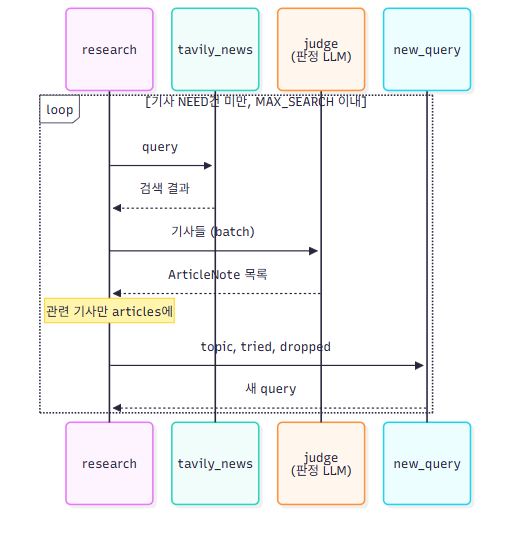

<details>
<summary>mermaid 원본 (그림을 고칠 때 쓴다)</summary>

```mermaid
%%{init: {"sequence": {"actorMargin": 24, "width": 110, "noteMargin": 6, "boxMargin": 6}}}%%
sequenceDiagram
    participant R as research
    participant T as tavily_news
    participant J as judge<br/>(판정 LLM)
    participant Q as new_query
    loop 기사 NEED건 미만, MAX_SEARCH 이내
        R->>T: query
        T-->>R: 검색 결과
        R->>J: 기사들 (batch)
        J-->>R: ArticleNote 목록
        Note over R: 관련 기사만 articles에
        R->>Q: topic, tried, dropped
        Q-->>R: 새 query
    end
```

</details>

In [17]:
NEED = 3
MAX_SEARCH = 3

def new_query(topic, tried, dropped):
    prompt = f"""주제에 맞는 해외 및 미국 시장 관련 기사가 더 나오도록 새로운 검색어를 한 줄로 만드세요.
미국 중간선거, 주가지수, AI 데이터센터·반도체·전력 인프라 기업과 같은 구체적인 키워드를 넣어 검색 범위를 좁히세요.
이미 쓴 검색어와 다른 표현을 사용하고, 검색어만 출력하세요.

[주제]
{topic}

[이미 쓴 검색어]
{tried}

[제외된 기사]
{dropped}
"""
    return llm.invoke(prompt).content.strip()

In [18]:
def research(topic):
    articles = []
    seen = set()
    tried = []
    dropped = []
    query = topic

    for search_no in range(1, MAX_SEARCH + 1):
        items = tavily_news(query)
        tried.append(query)
        texts = [f"제목: {item['title']}\n내용: {item.get('content', '')[:1500]}" for item in items]
        notes = judge.batch(texts) if texts else []
        excluded = 0

        for item, note in zip(items, notes):
            if not is_relevant(note):
                dropped.append(f"{note.country}·{note.topic}: {item['title'][:40]}")
                excluded += 1
                continue

            url = item["url"]
            if url not in seen:
                seen.add(url)
                articles.append({
                    "title": item["title"],
                    "url": url,
                    "date": ymd(item),
                    "summary": note.summary,
                })

        print(f"[조사원 검색 {search_no}] {query} → 관련 누적 {len(articles)}건 (이번 제외 {excluded}건)")
        if len(articles) >= NEED:
            break
        query = new_query(topic, tried, dropped)

    return articles


articles = research(TOPIC)
for article in articles:
    print(f"{article['date']} | {article['title'][:60]}")

[조사원 검색 1] 미국 중간선거전 지수 및 AI인프라 주식 동향 → 관련 누적 3건 (이번 제외 2건)
날짜 없음 | 미국 중간선거 대시보드｜stpete
날짜 없음 | Instagram
날짜 없음 | 주간 오세아니아 (10/4~10/9) #호주달러 #호주경제 #뉴질랜드경제 26/10/10｜Yan氏@グローバル


In [19]:
# ✅ 확인 (고치지 않는다)
assert isinstance(articles, list)
for a in articles:
    assert set(a) == {"title", "url", "date", "summary"}, "기사 딕셔너리의 키를 지시와 맞추세요"
assert len({a["url"] for a in articles}) == len(articles), "같은 기사(url)가 두 번 들어갔습니다"
print(len(articles), "건 — 통과")

3 건 — 통과


**관찰 포인트** — 내 실행 결과로 답한다

- 검색을 몇 번 했나? 재검색했다면 새 검색어에 무엇이 들어갔나 (한국 기관명 등)?
- 관련으로 들어온 기사를 읽어 본다. 주제("생성형 AI 교육 정책")와 정말 맞는가? 맞지 않는데 통과한 기사가 있다면, 판정 계약의 무엇이 넓어서인가?

### 1-4. 오류 대응 — 뉴스가 아닌 일반 검색으로 부르면?

`topic`을 빼면 Tavily는 일반 웹 검색을 한다. 같은 날짜 처리 코드를 그대로 쓰면 어떻게 되는지 본다.

**1-1의 호출과 비교** — 주소(`/search`)와 키 전달 방식(`Authorization` 헤더)은 같다. 요청 본문에서 `topic`과 `time_range`만 뺀다.

```python
# 1-1 뉴스 검색: 뉴스만, 최근 한 달 → 결과에 published_date가 붙는다
body = {"query": query, "topic": "news", "time_range": "month", "max_results": 5}

# 1-4 일반 검색: topic 기본값 general, 기간 제한 없음 → 일반 웹 페이지
body = {"query": TOPIC, "max_results": 3}
```

In [20]:
key = os.getenv("TAVILY_API_KEY")
body = {"query": TOPIC, "max_results": 3}
response = requests.post(
    "https://api.tavily.com/search",
    json=body,
    headers={"Authorization": f"Bearer {key}"},
    timeout=30,
)
response.raise_for_status()
general = response.json()["results"]

for r in general:
    print("published_date:", r.get("published_date"))
    try:
        print("ymd:", ymd(r))
    except Exception as e:
        print(type(e).__name__, str(e))

published_date: None
ymd: 날짜 없음
published_date: None
ymd: 날짜 없음
published_date: None
ymd: 날짜 없음


**관찰 포인트** — 내 실행 결과로 답한다

- 일반 검색 결과에 `published_date`가 있었나? `ymd()`는 어떻게 됐나?
- 외부 API의 필드를 쓰기 전에 무엇을 먼저 해야 하나? 없을 수 있는 필드는 어떻게 읽어야 하나?
- 조사원이 넘기는 기사 딕셔너리(`title`·`url`·`date`·`summary`)를 **팀 안의 데이터 계약**으로 두면, API 응답이 바뀔 때 어디만 고치면 되나?

## Part 2. 작성자와 출처 게이트

**전체 그림 2/3**: Part 1의 `articles`로 브리핑을 쓰고, 출처(코드)와 사실(LLM)을 검사하는 게이트를 만든다 → Part 3이 이 부품을 노드로 감싼다.

본 실습의 게이트는 스타일(코드) + 루브릭(검증자)이었다. 웹 자료 보고서에서 가장 중요한 품질은 **출처**다.

| 검사 | 누가 | 방법 |
| --- | --- | --- |
| 문단마다 기사 번호가 있는가, 없는 번호를 쓰지 않았는가 | 코드 | 문자열 검사 — 규칙이 분명하다 |
| 기사에 없는 사실을 썼는가 | 검증자(LLM) | 구조화 출력. 단, 지적한 문장이 브리핑에 실제로 있는지 코드로 확인한다 |
| 통과인가 | 코드 | 위반이 0건이면 통과 |

### 2-1. 작성자 — 기사 번호를 단 브리핑

In [ ]:
def articles_to_text(articles):
    lines = []
    for i, article in enumerate(articles, start=1):
        lines.append(f"[{i}] {article['title']} ({article['date']})")
        lines.append(article["summary"])
        lines.append("")
    return "\n".join(lines)


def write_brief(topic, articles, feedback="", previous=""):
    prompt = f"""당신은 뉴스 브리핑 작성자입니다. 오늘은 {TODAY}입니다.
                기사 요약에 있는 내용만으로 한국어 브리핑을 작성하세요.
                형식은 제목 한 줄, 핵심 요약 3줄, 주요 내용 3~4문단입니다.
                핵심 요약의 각 줄과 모든 문단 끝에는 근거 기사 번호를 [1]처럼 붙이세요.
                기사 요약에 없는 내용은 추가하지 마세요.

                [주제]
                {topic}

                [기사 요약]
                {articles_to_text(articles)}"""

    if feedback:
        prompt += f"""\n\n[이전 브리핑]
{previous}
\n[검증 게이트의 지적]
{feedback}
지적된 곳만 고치고 나머지는 그대로 유지하세요. 기사 요약에 없는 내용은 지우고, 고친 전체를 출력하세요."""

    return llm.invoke(prompt).content.strip()


brief = write_brief(TOPIC, articles)
print(brief)

**미국 중간선거와 AI 인프라 주식 동향**

미국 중간선거를 앞두고 주식 시장은 V자형 궤적을 보이며, 선거 전후로 각각 평균 19% 하락과 15% 상승하는 경향이 있다. [1] 정치적 불확실성이 해소되면 AI 산업에 긍정적인 영향을 미칠 것으로 예상된다. [1] 공화당의 승리가 예상될 경우, 원자력, 방산, 코인 등 다양한 분야에서 투자 기회가 제시되고 있다. [2]

미국 중간선거 대시보드에 따르면, 선거 전에는 주식 시장이 평균 19% 하락하는 경향이 있으며, 선거 후에는 평균 15% 상승하는 패턴이 관찰된다. [1] 2026년의 시장 환경은 과거와 다를 것으로 보이지만, 정치적 불확실성이 해소되면 AI 산업에 긍정적인 영향을 미칠 것으로 예상된다. 의회 정체는 메가테크 기업의 AI 투자에 순풍이 될 수 있다. [1]

공화당의 승리가 예상될 경우, 관련 산업에 대한 정책 기대가 커지며, 원자력, 방산, 코인, 조선, 반도체, 우주항공 등 다양한 분야에서의 투자 기회가 제시되고 있다. [2] 이러한 산업들은 정치적 변화에 따라 긍정적인 영향을 받을 것으로 보인다. [2]

또한, 최근 주간 오세아니아 경제 동향에서는 호주와 뉴질랜드의 주식 시장 상승세와 하락세, AI 자본 사이클의 변화 및 신용 수축 징후를 분석하였다. [3] 이러한 경제적 변화는 미국 중간선거와 관련된 글로벌 경제 환경에도 영향을 미칠 것으로 예상된다. [3]


In [22]:
# ✅ 확인 (고치지 않는다)
sample = [{"title": "가", "url": "u1", "date": "2026-01-01", "summary": "요약1"},
          {"title": "나", "url": "u2", "date": "2026-01-02", "summary": "요약2"}]
text = articles_to_text(sample)
assert text.startswith("[1] 가 (2026-01-01)\n요약1\n"), "articles_to_text 형식을 지시와 맞추세요"
assert "[2] 나 (2026-01-02)\n요약2" in text
print("통과")

통과


### 2-2. 출처 검사기 — 코드로 잴 수 있는 품질

| 위반 | 판정 방법 |
| --- | --- |
| 없는 기사 번호 | 기사가 3건인데 `[4]`~`[29]`가 브리핑에 나온다 |
| 번호 없는 문단 | 80자가 넘는 문단에 `[1]`~`[29]`가 하나도 없다 (제목·짧은 줄은 뺀다) |

In [23]:
def check_citations(brief, n_articles):
    violations = []

    for n in range(n_articles + 1, 30):
        if f"[{n}]" in brief:
            violations.append(f"없는 기사 번호 [{n}] (기사는 {n_articles}건)")

    valid_numbers = [f"[{n}]" for n in range(1, 30)]
    for paragraph in brief.split("\n\n"):
        if len(paragraph) > 80 and not any(number in paragraph for number in valid_numbers):
            violations.append(
                f"기사 번호가 없는 문단 (끝에 근거 번호를 붙일 것): {paragraph[:30]}…"
            )

    return violations


print(check_citations(brief, len(articles)))

[]


In [24]:
# ✅ 확인 (고치지 않는다)
fake = "제목\n\n" + "가" * 90 + " [1]\n\n" + "나" * 90 + " [7]\n\n" + "다" * 90
got = check_citations(fake, 3)
print(got)
assert len(got) == 2, "위반은 2건이어야 합니다 (없는 번호 [7], 번호 없는 '다' 문단)"
assert got[0] == "없는 기사 번호 [7] (기사는 3건)"
assert got[1].startswith("기사 번호가 없는 문단") and "다다다" in got[1]
assert check_citations("짧은 제목\n\n" + "라" * 90 + " [2]", 3) == []
print("통과")

['없는 기사 번호 [7] (기사는 3건)', '기사 번호가 없는 문단 (끝에 근거 번호를 붙일 것): 다다다다다다다다다다다다다다다다다다다다다다다다다다다다다다…']
통과


### 2-3. 사실 검증자 — 코드로 못 재는 품질

검증자에게 "기사 요약에 없는 사실을 담은 문장"을 **브리핑의 문장 그대로** 옮기게 한다. 그리고 옮긴 문장이 브리핑에 실제로 있는지 코드로 확인한다.

| 검증자 계약에 적은 판정 기준 | 이유 (이 노트북을 만들 때 실제로 겪은 것, 2026-09-27) |
| --- | --- |
| 번호가 여러 개면 그 기사들을 **합쳐서** 본다 | 기사 [2]와 [4]를 합쳐 쓴 문장을 "근거 없음"으로 세 번 연속 지적했다 → 작성자가 고칠 것이 없어 giveup |
| 표현이 달라도 뜻이 같으면 근거가 있다 | "모델 개발"을 "모델 구축"으로 바꿔 쓴 것도 걸렸다 |
| 지적된 문장을 **하나씩 다시 묻는다** (`recheck`) | 기준을 적어도, 브리핑 전체를 한꺼번에 보면 기사 [1] 요약에 그대로 있는 문장을 여전히 걸었다 |

본 실습 1-2의 "감점 기준을 항목 설명에 적는다"와 같은 이야기다. 기준이 없으면 검증자는 너무 너그럽거나(본 실습) **너무 엄격하다**(이번). 너무 엄격한 검증자는 루프를 제자리에 돌게 한다.

> ⚠️ 이 노트북을 만들며 지적한 문장이 브리핑에 있는지 확인하지 않고 돌렸더니, 검증자가 **브리핑에 없는 문장**을 지적했고 작성자가 그 문장을 고치려다 재시도 한도를 다 썼다 (같은 가짜 지적이 세 번 되풀이). 검증자의 지적도 검사 대상이다 (본 실습 Part 2-확장 "검증자 시험"과 같은 원칙).

In [25]:
class FactCheck(BaseModel):
    unsupported: list[str] = Field(description="브리핑에서 그대로 옮겨 적은 문장 중 기사 요약 어디에도 없는 사실(수치·날짜·기관·사건)을 담은 문장 목록. 문장 끝 번호가 여러 개면 해당 기사들을 합쳐서 판단하고, 표현이 달라도 뜻이 같으면 근거가 있는 것으로 본다. 없으면 빈 목록")


class Support(BaseModel):
    evidence: str = Field(description="이 문장을 뒷받침하는 기사 요약 구절을 그대로 옮긴다. 근거가 없으면 빈 문자열")
    supported: bool = Field(description="evidence가 문장의 사실을 모두 뒷받침하면 True")


fact_checker = llm.with_structured_output(FactCheck)
supporter = llm.with_structured_output(Support)


def recheck(sentence, articles):
    prompt = f"""[기사 요약]
{articles_to_text(articles)}

[문장]
{sentence}

이 문장의 사실이 기사 요약에 있는가? 기사 요약에 있는 구절을 먼저 그대로 옮긴 뒤, 문장의 모든 사실이 근거로 뒷받침되는지 판단하세요."""
    return supporter.invoke(prompt).supported

In [26]:
# ✅ 확인 (고치지 않는다)
assert list(FactCheck.model_fields) == ["unsupported"]
assert list(Support.model_fields) == ["evidence", "supported"], "Support는 evidence를 먼저 둡니다"
print("통과")

통과


In [27]:
def check_facts(brief, articles):
    prompt = f"""당신은 사실 검증자입니다.
[기사 요약]
{articles_to_text(articles)}

[브리핑]
{brief}

기사 요약 어디에도 없는 사실(수치·날짜·기관·사건)을 담은 문장을 브리핑의 문장 그대로 적으세요.
여러 기사에 걸친 문장은 관련 기사들을 모두 합쳐 판단하고, 표현만 다르고 뜻이 같은 문장은 지적하지 마세요.
근거 없는 문장이 없으면 빈 목록을 반환하세요."""
    result = fact_checker.invoke(prompt)
    violations = []
    normalized_brief = " ".join(brief.split())

    for sentence in result.unsupported:
        normalized_sentence = " ".join(sentence.split())
        if normalized_sentence[:25] not in normalized_brief:
            print("(브리핑에 없는 문장을 지적해 버림)", sentence)
            continue
        if recheck(sentence, articles):
            print("(재확인해 보니 근거가 있어 버림)", sentence)
            continue
        violations.append(f"근거 없는 문장: {sentence}")

    return violations


print(check_facts(brief, articles))

[]


### 2-4. 게이트 — 통과 판정은 코드가 한다

In [28]:
def gate(brief, articles):
    violations = check_citations(brief, len(articles))
    violations += check_facts(brief, articles)
    passed = len(violations) == 0
    return passed, violations


passed, violations = gate(brief, articles)
print("통과:", passed)
for violation in violations:
    print(violation)

통과: True


**관찰 포인트** — 내 실행 결과로 답한다

- 출처 검사와 사실 확인에서 각각 몇 건이 걸렸나? 출처 검사에 자주 걸리는 규칙이 있다면, 게이트 말고 어디에도 넣어야 하나?
- 검증자의 지적 중 버려진 것이 있었나 (브리핑에 없는 문장, 재확인해 보니 근거 있음)? 이 거르기가 없었다면 어떻게 됐을까?
- 같은 셀을 한 번 더 돌리면 출처 검사와 사실 확인 중 어느 쪽 결과가 바뀌나? 왜 그런가?

## Part 3. 팀 그래프 — 조사원 → 작성자 → 게이트

**전체 그림 3/3**: 조사원·작성자·게이트를 한 그래프로 잇고, 미달이면 작성자에게 되돌린다.

본 실습 캡스톤과 같은 틀이다. 게이트 미달이면 **작성자로만** 되돌아간다. 조사는 다시 하지 않는다 → 재시도 비용(검색·판정 호출)을 줄인다.

재시도 때 작성자는 **이전 브리핑**과 지적을 함께 받아 지적된 곳만 고친다 (2-1의 `previous` 인자).

> ⚠️ 이 노트북을 만들 때(2026-09-27) 처음에는 재시도마다 **처음부터 새로** 쓰게 했다. 세 번 모두 "핵심 요약" 문단에 번호를 빠뜨리고 요약 문장 하나를 근거 없이 썼다 → 위반 2건으로 giveup. 새로 쓰면 같은 실수를 다시 할 기회도 새로 생긴다. 지적된 곳만 고치게 하는 것은 본 실습 2-1 "알고 다시"를 한 걸음 더 좁힌 것이다.

```text
주제 → researcher → writer → gate → pass / giveup → 끝
                       ↑        │ retry (위반 목록을 피드백으로)
                       └────────┘
```

| 멈춤 조건 | 판정 |
| --- | --- |
| 위반 0건 | pass |
| 재시도 한도(`MAX_ROUNDS`)에 도달 | giveup — **위반이 가장 적었던 버전**을 채택 |
| 조사원이 기사를 하나도 못 모음 | no_source — 쓰지 않고 멈춘다 (3-3) |

### 3-1. TeamState와 노드

In [30]:
MAX_ROUNDS = 3


class WebTeamState(TypedDict):
    topic: str
    articles: list[dict]
    brief: str
    feedback: str
    attempts: int
    best_brief: str
    best_violations: int
    verdict: str


def researcher_node(state):
    return {"articles": research(state["topic"])}


def writer_node(state):
    if not state["articles"]:
        return {"verdict": "no_source"}

    attempts = state["attempts"] + 1
    brief = write_brief(
        state["topic"],
        state["articles"],
        state.get("feedback", ""),
        state.get("brief", ""),
    )
    return {"brief": brief, "attempts": attempts}

In [31]:
def gate_node(state):
    passed, violations = gate(state["brief"], state["articles"])
    attempts = state["attempts"]
    print(f"[게이트 {attempts}차] 위반 {len(violations)}건")
    for violation in violations:
        print(violation)

    verdict = (
        "pass"
        if passed
        else "giveup"
        if attempts >= MAX_ROUNDS
        else "retry"
    )
    update = {
        "feedback": "\n".join(f"- {v}" for v in violations),
        "verdict": verdict,
    }

    if len(violations) < state["best_violations"]:
        update.update({"best_brief": state["brief"], "best_violations": len(violations)})
    return update


def route_after_writer(state):
    return "end" if state["verdict"] == "no_source" else "gate"


def route_after_gate(state):
    return "writer" if state["verdict"] == "retry" else "end"

In [32]:
# ✅ 확인 (고치지 않는다) — 라우터만 본다 (LLM·검색 없음)
assert route_after_writer({"verdict": "no_source"}) == "end"
assert route_after_writer({"verdict": ""}) == "gate"
assert route_after_gate({"verdict": "retry"}) == "writer"
assert route_after_gate({"verdict": "pass"}) == "end"
assert route_after_gate({"verdict": "giveup"}) == "end"
print("통과")

통과


### 3-2. 그래프 조립·실행

**함수 흐름 (시퀀스)** — 조사는 한 번, 작성과 게이트는 판정이 `retry`인 동안 반복한다. 자료가 하나도 없으면 작성자가 `no_source`를 내고 바로 끝난다.

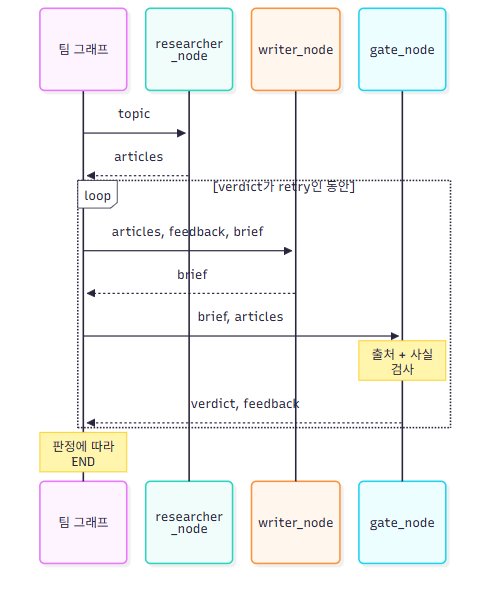

<details>
<summary>mermaid 원본 (그림을 고칠 때 쓴다)</summary>

```mermaid
%%{init: {"sequence": {"actorMargin": 24, "width": 110, "noteMargin": 6, "boxMargin": 6}}}%%
sequenceDiagram
    participant G as 팀 그래프
    participant R as researcher<br/>_node
    participant W as writer_node
    participant GT as gate_node
    G->>R: topic
    R-->>G: articles
    loop verdict가 retry인 동안
        G->>W: articles, feedback, brief
        W-->>G: brief
        G->>GT: brief, articles
        Note over GT: 출처 + 사실<br/>검사
        GT-->>G: verdict, feedback
    end
    Note over G: 판정에 따라<br/>END
```

</details>

In [33]:
graph = StateGraph(WebTeamState)
graph.add_node("researcher", researcher_node)
graph.add_node("writer", writer_node)
graph.add_node("gate", gate_node)
graph.add_edge(START, "researcher")
graph.add_edge("researcher", "writer")
graph.add_conditional_edges("writer", route_after_writer, {"gate": "gate", "end": END})
graph.add_conditional_edges("gate", route_after_gate, {"writer": "writer", "end": END})
web_team = graph.compile()


def start_state(topic):
    return {
        "topic": topic,
        "articles": [],
        "brief": "",
        "feedback": "",
        "attempts": 0,
        "best_brief": "",
        "best_violations": 999,
        "verdict": "",
    }

In [34]:
# ✅ 확인 (고치지 않는다)
s = start_state(TOPIC)
assert set(s) == set(WebTeamState.__annotations__), "start_state가 WebTeamState의 칸을 모두 채워야 합니다"
assert s["best_violations"] > 100 and s["attempts"] == 0
assert set(web_team.get_graph().nodes) >= {"researcher", "writer", "gate"}
print("통과")

통과


In [35]:
result = web_team.invoke(start_state(TOPIC))
print(f"[판정] {result['verdict']} | 작성 {result['attempts']}회 | 채택본 위반 {result['best_violations']}건")
print("\n[채택본]")
print(result["best_brief"])
print("\n[기사 목록]")
for i, article in enumerate(result["articles"], start=1):
    print(f"[{i}] {article['date']} {article['title'][:50]} | {article['url']}")

[조사원 검색 1] 미국 중간선거전 지수 및 AI인프라 주식 동향 → 관련 누적 3건 (이번 제외 2건)
[게이트 1차] 위반 0건
[판정] pass | 작성 1회 | 채택본 위반 0건

[채택본]
**미국 중간선거와 AI 인프라 주식 동향**

미국 중간선거를 앞두고 주식 시장은 V자형 궤적을 보이며, 선거 전 평균 19% 하락 후 선거 후 평균 15% 상승하는 경향이 있다[1]. 의회 정체는 AI 산업에 긍정적인 영향을 미치고 있으며, 미국과 일본 주식 간의 디커플링 현상이 나타나고 있다[1]. 공화당의 승리가 예상될 경우, 원자력, 방산, 코인, 조선, 반도체, 우주항공 등 다양한 분야에서 투자 기회가 제시된다[2].

미국 중간선거를 기점으로 주식 시장은 전반적으로 V자형 궤적을 보이는 경향이 있다. 선거 전에는 평균적으로 19% 하락하지만, 선거 후에는 100%의 승률로 평균 15% 상승하는 모습을 보인다[1]. 이러한 패턴은 투자자들에게 중요한 참고자료가 될 수 있다.

특히, 의회 정체는 AI 산업에 긍정적인 영향을 미친다고 분석되고 있다. 이는 AI 관련 주식의 성장을 촉진할 수 있는 요소로 작용할 가능성이 높다[1]. 또한, 미국 주식과 일본 주식 간의 디커플링 현상이 나타나고 있어, 두 시장 간의 상관관계가 약화되고 있는 상황이다[1].

공화당의 승리가 예상될 경우, 관련 산업에 대한 정책 기대가 커지며, 원자력, 방산, 코인, 조선, 반도체, 우주항공 등 다양한 분야에서의 투자 기회가 제시된다[2]. 이러한 정책 흐름과 실제 사업 성과를 비교하는 것이 중요하다는 점도 강조된다[2].

[기사 목록]
[1] 날짜 없음 미국 중간선거 대시보드｜stpete | https://note.com/stpeteishii/n/n6feeadc08c8b?hl=ko
[2] 날짜 없음 Instagram | https://www.instagram.com/p/DeOrwUTiT5L
[3] 날짜 없음 주간 오세아니아 (10/4~10/9) #호주달러 #호주경제 #뉴질랜드

**관찰 포인트** — 내 실행 결과로 답한다

- 몇 번 만에 끝났고 판정은 무엇이었나? 재시도가 있었다면 두 번째 브리핑에서 무엇이 바뀌었나?
- 채택본의 `[번호]`를 기사 목록과 대조해 본다. 번호가 가리키는 기사에 그 내용이 정말 있는가?
- 같은 주제로 내일 다시 돌리면 결과가 같을까? 보고서에 무엇을 함께 남겨야 하나?

### 3-3. 자료가 없을 때 — no_source

조사원이 관련 기사를 하나도 못 모으면 작성자는 무엇을 근거로 쓰는가? 조사원을 건너뛰고 **빈 기사 목록**으로 작성자 노드를 직접 불러 본다 (검색 비용 없이 확인).

In [36]:
# Capstone 웹 조사 팀 노드 테스트: 작성자 노드와 라우터를 단독으로 실행
empty = start_state(TOPIC)
# Capstone 작성자 노드 실행
print("작성자 노드 결과:", writer_node(empty))
# Capstone 작성자 노드 이후 라우터 실행
print("다음 행선지:", route_after_writer({**empty, "verdict": "no_source"}))

작성자 노드 결과: {'verdict': 'no_source'}
다음 행선지: end


**관찰 포인트** — 내 실행 결과로 답한다

- 작성자는 빈 기사 목록을 받고 무엇을 돌려줬나? 그래프는 그다음 어디로 가나?
- 이 확인이 없다면 작성자는 무엇을 근거로 쓸까? 게이트의 출처 검사가 이런 글을 막을 수 있을까?

## 확인 문제

1. 본 실습 캡스톤에 없던 역할이 이번에 하나 더해졌다. 무엇이고, 왜 필요해졌나?
2. `ArticleNote`에서 `place`를 `country`보다 먼저 두는 이유는?
3. 조사원이 검색어를 바꿀 때 `tried`(이미 쓴 검색어)와 `dropped`(제외된 기사)를 넘기는 이유는?
4. 출처 검사는 코드로, 사실 확인은 LLM으로 나눈 이유는?
5. 게이트 미달 시 조사원이 아니라 작성자로만 되돌아가는 이유는?
6. 기사가 0건일 때 작성자가 쓰지 않고 멈추게 한 이유는?

## 정리·회고

| 본 실습 캡스톤 | 이번 확장 |
| --- | --- |
| 자료가 주어진다 (`SOURCE`) | 조사원이 웹에서 찾고 거른다 |
| 분석가 4명 병렬 → 통합자 | 조사원 → 작성자 (순차) |
| 게이트: 스타일(코드) + 루브릭(LLM) | 게이트: 출처(코드) + 사실 확인(LLM, 지적도 코드로 확인) |
| 미달 → 통합자 재시도 | 미달 → 작성자 재시도 |
| 최고 버전 = 위반 없음 우선, 그다음 점수 | 최고 버전 = 위반이 가장 적은 것 |

1. 조사원·작성자·검증자 중 LLM이 틀렸을 때 가장 큰 피해를 내는 역할은 어느 것인가? 그 역할의 출력을 누가 확인하는가?
2. 오늘 팀에 병렬(Day 4)을 넣는다면 어느 단계에 넣겠는가?